In [30]:
# Problem 1
f = lambda x: 924 * x ** 6 - 2772 * x ** 5 + 3150 * x ** 4 - 1680 * x ** 3 + 420 * x ** 2 - 42 * x + 1
fp = lambda x: 6 * 924 * x ** 5 - 2772 * 5 * x ** 4 + 3150 * 4 * x ** 3 - 1680 * 3 * x ** 2 + 420 * 2 * x - 42

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import math

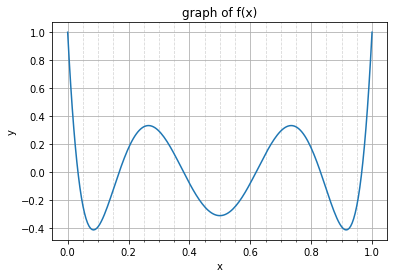

In [27]:
xs = np.linspace(0, 1, 200)
ys = f(xs)

fig = plt.figure(0)

plt.plot(xs, ys)
ax = fig.axes[0]
ax.set_xticks(np.linspace(0, 1, 6))
ax.set_xticks(np.linspace(0, 1, 21), minor=True)
plt.title("graph of f(x)")
plt.xlabel("x")
plt.ylabel("y")
# plt.hlines([0], [0], [1], 'gray', '--')
ax.grid(which='both')
ax.grid(which='minor', linestyle='--', alpha=0.5)

plt.show()

We can estimate that the zero points of this funtion are $x\approx 0.035, 0.165, 0.375, 0.62, 0.835, 0.96$

In [44]:
# newton's method

def newton(f, fp, x0, err, max_iter) -> tuple[float, bool]:
    x1 = x0 - f(x0) / fp(x0)
    i = 0
    while np.abs(x1 - x0) >= err and max_iter >= i and np.abs(fp(x1)) > err:
        x0 = x1
        x1 = x1 - f(x1) / fp(x1)
        i += 1
    return x1, np.abs(x1 - x0) < err


In [50]:
err = 1e-8
max_iter = 10000
x0s = [0.035, 0.165, 0.375, 0.62, 0.835, 0.96]
zeros = list(map(lambda x: newton(f, fp, x, err, max_iter), x0s))
print("Zero points:")
print(zeros)
values = list(map(f, list(map(lambda x: x[0], zeros))))
print("Function value errors:")
print(values)

Zero points:
[(0.03376524289842327, True), (0.1693953067668674, True), (0.3806904069583994, True), (0.6193095930415999, True), (0.8306046932331234, True), (0.9662347571016062, True)]
Function value errors:
[1.354472090042691e-14, -3.552713678800501e-15, 1.4210854715202004e-14, -1.4210854715202004e-14, -2.1316282072803006e-13, 1.9895196601282805e-13]


In [65]:
# Problem 2

# (a)

A = np.array([
    [1, 2, 1],
    [2, -1, 0],
    [0.5, 1, -2]
])
b = np.array([[3], [2], [1]])

x = np.linalg.pinv(A) @ b
print("Solution:\n", x)
print("Verify Ax - b: \n", A @ x - b)
# it's correct

Solution:
 [[1.36]
 [0.72]
 [0.2 ]]
Verify Ax - b: 
 [[2.22044605e-15]
 [0.00000000e+00]
 [1.55431223e-15]]


In [63]:
# (b)

Ap = np.matrix('1 2 1; 2 -1 0; 0.5 1 -2')
bp = np.matrix('3; 2; 1')

xp = Ap.getI() @ bp
print("Solution:\n", xp)
print("Verify Ax - b: \n", Ap @ xp - bp)  # type: ignore
# it's correct

Solution:
 [[1.36]
 [0.72]
 [0.2 ]]
Verify Ax - b: 
 [[8.88178420e-16]
 [4.44089210e-16]
 [2.22044605e-16]]


In [75]:
# (c)

evs = np.linalg.eigvals(A)
print("Eigenvalues are: \n", evs)
print("Are these eigenvalues real? \n", np.isreal(evs))
print("The eigenvalues are distinct from each other.\n")

evecs = np.linalg.eig(A)[1]
print("Eigen vector 1: ", evecs[0])
print("Eigen vector 2: ", evecs[1])
print("Eigen vector 3: ", evecs[2])

Eigenvalues are: 
 [ 2.41653324+0.j        -2.20826662+0.5442958j -2.20826662-0.5442958j]
Are these eigenvalues real? 
 [ True False False]
The eigenvalues are distinct from each other.

Eigen vector 1:  [ 0.84422736+0.j         -0.09593819-0.37517014j -0.09593819+0.37517014j]
Eigen vector 2:  [ 0.49420117+0.j         -0.10054244+0.57571354j -0.10054244-0.57571354j]
Eigen vector 3:  [0.20747378+0.j 0.71308371+0.j 0.71308371-0.j]
